(16 Oct 2026: JY and JM)

## Notebook for the sloped Phillips problem focusing on transient growth

Focusing only here on the cases
* $\gamma = 0$, $\delta\neq 0$ (no planetary $\beta$, with slope)
* $\gamma > 0$, $\delta = 0$ (with planteary $\beta$, no slope)

Figures mirror those in the sloped Eady transient case.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D
from scipy.linalg import expm, svd, eig, sqrtm, eigh
from scipy.optimize import fsolve
zi = 1j

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "mathtext.fontset": "cm",
    "mathtext.rm": "serif",
    "font.size": 11,
    "image.cmap": "RdBu_r"
})

letters = "abcdefghijklmnopqrstuvwxyz"

## 0) Define some useful subroutines to be called later

In [2]:
def Phillips_A(k, l, gamma, delta):
    K2 = k**2 + l**2
    factor = -zi*k / (K2 * (K2 + 8))
    H11 = K2**2 - 4*gamma*(K2 + 4) - 32
    H12 = -32 - 16*gamma
    H21 = 32 - 16*gamma - 16*delta
    H22 = -K2**2 - 4*gamma*(K2 + 4) + 32 - 4*delta*(4+K2)

    return factor * np.asarray([[H11, H12], [H21, H22]])

def Phillips_M(k, l):   #Energy matrix for Phillips
    K2 = k**2 + l**2
    # L = np.array([
    #     [-(K2 + 4),  4],
    #     [ 4, -(K2 + 4)]
    # ])
    # Linvt = np.linalg.inv(L)

    Linvt = -1 / (K2 + 8) * np.array([
        [1 + 4 / K2, 4 / K2],
        [4 / K2, 1 + 4 / K2]
    ])

    Mpsi = np.array([
        [K2 + 4, -4],
        [-4, K2 + 4]
    ])

    Mq = Linvt.T @ Mpsi @ Linvt
    return Mq

def instantaneous(A, W):
    T = sqrtm(W)
    B = T @ A @ np.linalg.inv(T)
    eigvals, eigvecs = eig((B + B.conj().T)/2)
    idx = np.argmax(np.real(eigvals))
    growth = eigvals[idx]
    q_tilde = eigvecs[:, idx]
    q = np.linalg.inv(T) @ q_tilde
    return growth, q

def finite_time_optimal(t, A, M):
    P = expm(A * t)
    T = sqrtm(M)
    D = T @ P @ np.linalg.inv(T)
    _, S, Vh = svd(D)
    amp = S[0]
    x0 = Vh.conj().T[:, 0]
    q0 = np.linalg.inv(T) @ x0
    qt = P @ q0
    return amp, q0, qt

def dF(points, k, l, gamma, delta):
    K2 = k**2 + l**2
    deps, Gamma = points
    eps_dot = -2*k + 16*k / (K2 * (K2 + 8)) * (2/np.sin(Gamma)*(gamma*np.cos(2*Gamma)+2)*np.cos(deps)+4+K2) - 4*delta*k/(K2 * (K2+8)) * (4+K2+4*np.tan(Gamma)*np.cos(deps))
    Gamma_dot = 16*k/ (K2 * (K2 + 8)) * (gamma+2*np.cos(2*Gamma)+delta*np.sin(Gamma)**2) * np.sin(deps)
    return eps_dot, Gamma_dot

def get_root(dF, k, l, gamma, delta, guess_init):
    return fsolve(dF,guess_init,args=(k, l, gamma, delta))

def state_to_phase(q):
    qT, qB = q
    deps = np.angle(qT/qB)
    gamma = np.arctan(np.abs(qT/qB))
    return deps, gamma

def compute_optimal(T_vecs, A, M):
    deps_list = []
    gamma_list = []
    for T in T_vecs:
        _, q0, _ = finite_time_optimal(T, A, M)
        deps, Gamma = state_to_phase(q0)
        deps_list.append(deps)
        gamma_list.append(Gamma)
    return np.array(deps_list), np.array(gamma_list)

## 1) Dependence on boundary slope: $\gamma=0$, varying $\delta$.  

In [3]:
# compute growth rate, phase shift and amplitude ratio for NM and instantaneous in enstrophy and energy
# k_vec = np.linspace(1e-3, 4, 501)
k_vec = np.concat([10 ** np.linspace(-3, -1, 201), np.linspace(1e-1, 4, 301)])
delta_vec = [1.0, 0.0, -1.0]
l_vec = [0.0, 1.0]
# l = 0
gamma = 0.0

Sloped_growth_NM = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_eps_NM = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_Gamma_NM = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_growth_ens = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_eps_ens = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_Gamma_ens = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_growth_enr = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_eps_enr = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_Gamma_enr = np.zeros((len(k_vec), len(delta_vec), 2))
Sloped_Delta_max = np.zeros((len(k_vec), len(delta_vec), 2))
normality = np.zeros((len(k_vec), len(delta_vec), 2))
normality_enr = np.zeros((len(k_vec), len(delta_vec), 2))

for ll, l in enumerate(l_vec):
    for j, delta in enumerate(delta_vec):
        for i, k in enumerate(k_vec):
            A = Phillips_A(k, l, gamma, delta)
            M = Phillips_M(k, l)
            eigvals, eigvecs = eig(A)
            idx = np.argmax(np.real(eigvals))
            Sloped_growth_NM[i, j, ll] = np.real(eigvals[idx])
            if Sloped_growth_NM[i, j, ll]>1e-4:
                q = eigvecs[:, idx]
            else:
                id = np.argmax(np.imag(eigvals))
                q = eigvecs[:, id]
            Sloped_eps_NM[i, j, ll], Sloped_Gamma_NM[i, j, ll] = np.arccos(np.cos(np.angle(q[0]/q[-1]))), np.arctan(np.abs(q[0]/q[-1]))

            growth, q = instantaneous(A, np.eye(2))
            Sloped_growth_ens[i, j, ll] = np.real(growth)
            Sloped_eps_ens[i, j, ll], Sloped_Gamma_ens[i, j, ll] = state_to_phase(q)

            growth, q = instantaneous(A, M)
            Sloped_growth_enr[i, j, ll] = np.real(growth)
            Sloped_eps_enr[i, j, ll], Sloped_Gamma_enr[i, j, ll] = state_to_phase(q)

            commutator = A @ A.conj().T - A.conj().T @ A
            normality[i, j, ll] = np.linalg.norm(commutator)

            T = sqrtm(M)
            D = T @ A @ np.linalg.inv(T)
            commutator = D @ D.conj().T - D.conj().T @ D
            normality_enr[i, j, ll] = np.linalg.norm(commutator)

In [4]:
# compute NM growth k_max for diff. delta
Sloped_k_max = np.zeros((len(delta_vec), 2))
for ll in range(len(l_vec)):
    for j in range(len(delta_vec)):
        k_max_idx = np.argmax(Sloped_growth_NM[:, j, ll])
        Sloped_k_max[j, ll] = k_vec[k_max_idx]
        print(rf'delta={delta_vec[j]}, l={l_vec[ll]}, k_max={Sloped_k_max[j, ll]}')

delta=1.0, l=0.0, k_max=1.478
delta=0.0, l=0.0, k_max=1.816
delta=-1.0, l=0.0, k_max=2.362
delta=1.0, l=1.0, k_max=1.4000000000000001
delta=0.0, l=1.0, k_max=1.738
delta=-1.0, l=1.0, k_max=2.193


In [5]:
# compute effective optimal growth in enstrophy and energy norm for selected target time
# t_vals = np.linspace(0.0, 5.0, 201)
t_vals = [1.0, 3.0, 5.0]
# l = 0.0

Sloped_effective_ens = np.zeros((len(k_vec), len(delta_vec), len(t_vals), 2))
Sloped_effective_enr = np.zeros((len(k_vec), len(delta_vec), len(t_vals), 2))

for ll, l in enumerate(l_vec):
    for j, delta in enumerate(delta_vec):
        for i, k in enumerate(k_vec):
            A = Phillips_A(k, l, gamma, delta)
            M = Phillips_M(k, l)
            for d, t in enumerate(t_vals):
                amp_ens, _, _ = finite_time_optimal(t, A, np.eye(2)) # Euclidean norm growth
                amp_enr, _, _ = finite_time_optimal(t, A, M) # Energy norm growth
                Sloped_effective_ens[i, j, d, ll] = np.log(amp_ens)/t
                Sloped_effective_enr[i, j, d, ll] = np.log(amp_enr)/t

In [6]:
# compute streamfunction of optimal perturbation at selected target time in enstrophy and energy norm
z_vec = np.linspace(-1, 1, 31)
t = 5.0
Sloped_psi0_B = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
Sloped_psi0_T = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
# psit_B = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
# psit_T = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
Sloped_psi0_B_enr = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
Sloped_psi0_T_enr = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
# psit_B_enr = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
# psit_T_enr = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
for ll, l in enumerate(l_vec):
    for j, idx in enumerate([0, 1, 2]):
        delta = delta_vec[idx]
        for i, k_idx in enumerate([0, 1, 2]):
            K2 = k**2 + l**2
            k = Sloped_k_max[k_idx, ll]
            x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
            A = Phillips_A(k, l, gamma, delta)
            M = Phillips_M(k, l)
            _, q0, qt = finite_time_optimal(t, A, np.eye(2))
            _, q0_enr, qt_enr = finite_time_optimal(t, A, M)

            q0[0] /= q0[1]
            qt[0] /= qt[1]
            q0[1] = 1.0
            qt[1] = 1.0
            q0_enr[0] /= q0_enr[1]
            qt_enr[0] /= qt_enr[1]
            q0_enr[1] = 1.0
            qt_enr[1] = 1.0

            Z = z_vec[:, None]
            X = x_vec[None, :]
            Sloped_psi0_T[:, :, i, j, ll] = - np.exp(zi * k * X) * ((1 + 4 / K2) * q0[0] + (4 / K2) * q0[1]) / (K2 + 8)
            Sloped_psi0_B[:, :, i, j, ll] = - np.exp(zi * k * X) * ((4 / K2) * q0[0] + (1 + 4 / K2) * q0[1]) / (K2 + 8)

            # psit_B[:, :, i, j] = np.exp(zi * k * X) * (-qt[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
            # psit_T[:, :, i, j] = np.exp(zi * k * X) * (-qt[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

            Sloped_psi0_T_enr[:, :, i, j, ll] = - np.exp(zi * k * X) * ((1 + 4 / (K2)) * q0_enr[0] + (4 / K2) * q0_enr[1]) / (K2 + 8)
            Sloped_psi0_B_enr[:, :, i, j, ll] = - np.exp(zi * k * X) * ((4 / K2) * q0_enr[0] + (1 + 4 / K2) * q0_enr[1]) / (K2 + 8)

            # psit_B_enr[:, :, i, j] = np.exp(zi * k * X) * (-qt_enr[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
            # psit_T_enr[:, :, i, j] = np.exp(zi * k * X) * (-qt_enr[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

field0 = Sloped_psi0_T + Sloped_psi0_B
# fieldt = psit_T + psit_B
diff0 = np.angle(field0[-1, 0, :, :]/field0[0, 0, :, :])
# difft = np.angle(fieldt[-1, 0, :, :]/fieldt[0, 0, :, :])

field0_enr = Sloped_psi0_T_enr + Sloped_psi0_B_enr
# fieldt_enr = psit_T_enr + psit_B_enr
diff0_enr = np.angle(field0_enr[-1, 0, :, :]/field0_enr[0, 0, :, :])
# difft_enr = np.angle(fieldt_enr[-1, 0, :, :]/fieldt_enr[0, 0, :, :])

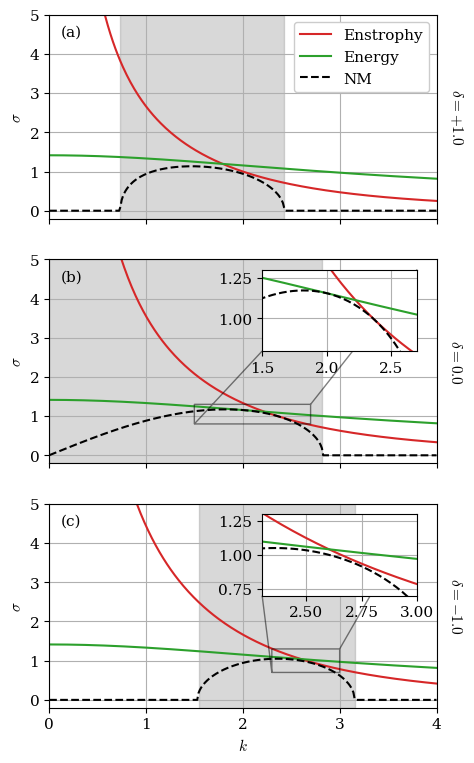

In [7]:
# growth rate
fig, axs = plt.subplots(3, 1, figsize=(5, 9), sharex=True)
ll = 0
for j, ax in enumerate(axs):
    ax.plot(k_vec, Sloped_growth_ens[:, j, ll],'C3', label='Enstrophy')
    ax.plot(k_vec, Sloped_growth_enr[:, j, ll],'C2', label='Energy')
    ax.plot(k_vec, Sloped_growth_NM[:, j, ll], 'k--', label='NM')
    ax.set_xlim(0, 4)
    ax.set_ylim(-0.2, 5.0)
    ax.set_ylabel(r"$\sigma$")
    k_shade_ind = np.where(Sloped_growth_NM[:, j, ll] > 1e-3)[0]
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.grid()
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.text(0.03, 0.95, f"({letters[j]})", transform=ax.transAxes, ha='left', va='top')
    # if j < 2:
    #     ax.tick_params(labelbottom=False)

    if j == 1:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Sloped_growth_ens[:, j, ll],'C3')
        ax_inset.plot(k_vec, Sloped_growth_enr[:, j, ll],'C2')
        ax_inset.plot(k_vec, Sloped_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(1.5, 2.7)
        ax_inset.set_ylim(0.8, 1.3)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")

    if j == 2:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Sloped_growth_ens[:, j, ll],'C3')
        ax_inset.plot(k_vec, Sloped_growth_enr[:, j, ll],'C2')
        ax_inset.plot(k_vec, Sloped_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(2.3, 3.0)
        ax_inset.set_ylim(0.7, 1.3)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")

for row, ax in enumerate(axs):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1].set_xlabel(r"$k$")
axs[0].legend(loc='upper right', framealpha=1.0)

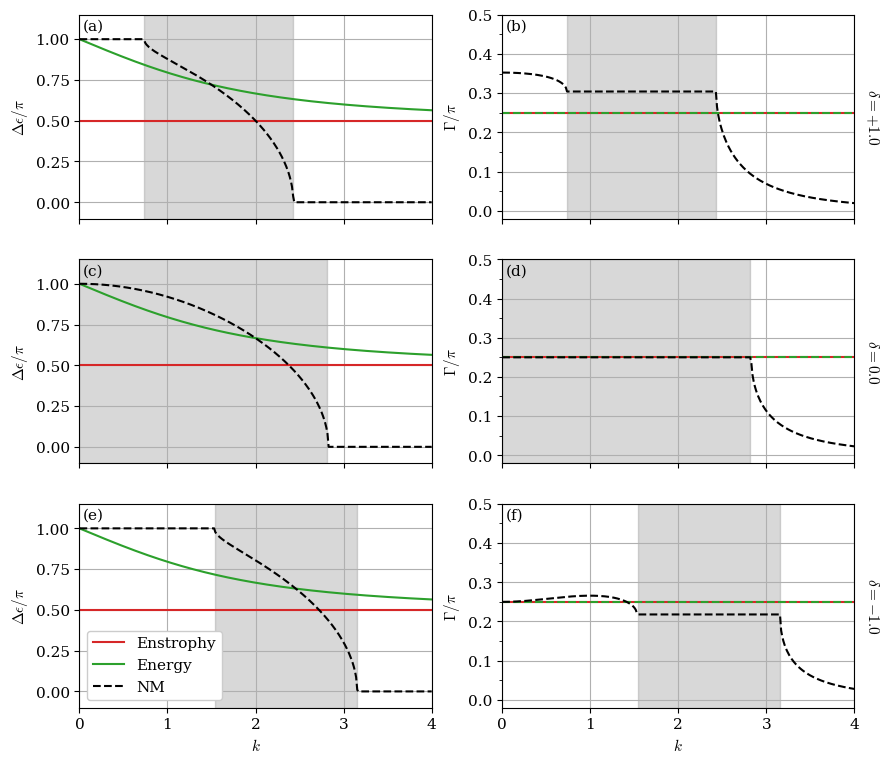

In [8]:
# CRW quantities
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
ll = 0
for j in range(3):
    k_shade_ind = np.where(Sloped_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    ax.plot(k_vec, Sloped_eps_ens[:, j, ll]/np.pi, 'C3', label='Enstrophy')
    ax.plot(k_vec, Sloped_eps_enr[:, j, ll]/np.pi, 'C2', label='Energy')
    ax.plot(k_vec, Sloped_eps_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylim([-0.1, 1.15])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylabel(r'$\Delta\epsilon/\pi$')
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    
    ax = axs[j, 1]
    ax.plot(k_vec, Sloped_Gamma_ens[:, j, ll]/np.pi, 'C3', label='Enstrophy')
    ax.plot(k_vec, Sloped_Gamma_enr[:, j, ll]/np.pi, 'C2--', label='Energy')
    ax.plot(k_vec, Sloped_Gamma_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylim(-0.02, 0.5)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.set_ylabel(r'$\Gamma/\pi$')
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top')  

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 4)
    ax.xaxis.set_major_locator(MultipleLocator(1.0))

# for ax in axs[0, :]:
#     ax.tick_params(labelbottom=False)

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1,0].legend(loc='lower left', framealpha=1.0)

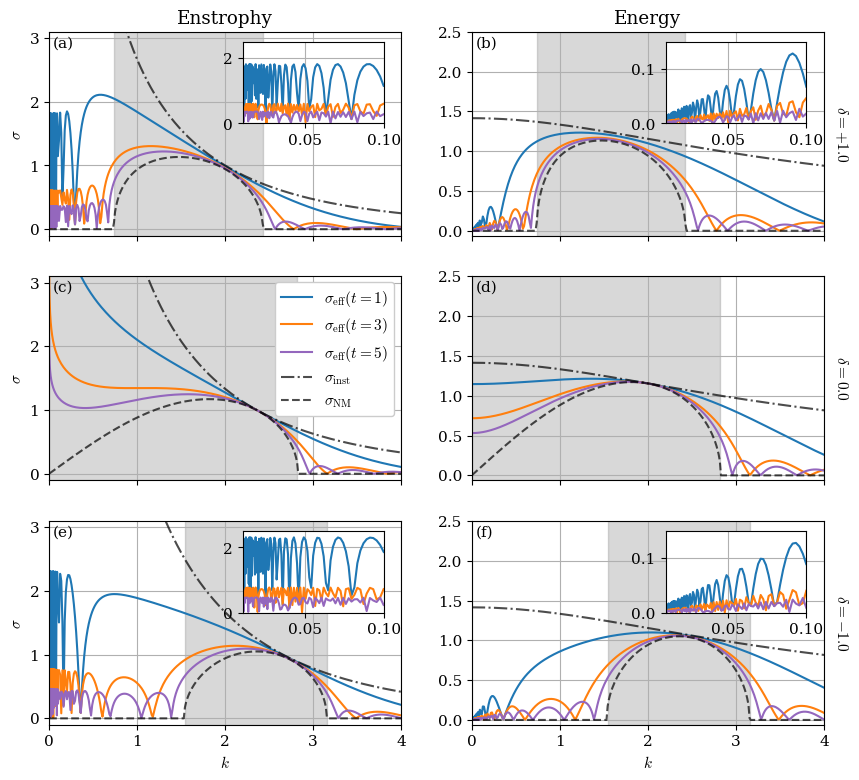

In [9]:
# effective optimal growth rate
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
colors = ['C0', 'C1', 'C4']
ll = 0
for j in range(3):
    k_shade_ind = np.where(Sloped_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Sloped_effective_ens[:, j, d, ll], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Sloped_growth_ens[:, j, ll], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Sloped_growth_NM[:, j, ll], 'k--', alpha=0.7, label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Enstrophy' if j == 0 else "")
    ax.set_ylim(-0.1, 3.1)
    # ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    ax.set_ylabel(r"$\sigma$")

    if j != 1:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        for d, t in enumerate(t_vals):
            ax_inset.plot(k_vec, Sloped_effective_ens[:, j, d, ll], color=colors[d])
        
        ax_inset.set_xlim(1e-2, 1e-1)
        ax_inset.set_ylim(0.0, 2.5)
        ax_inset.grid()
        # ax.indicate_inset_zoom(ax_inset, edgecolor="black")
    
    ax = axs[j, 1]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Sloped_effective_enr[:, j, d, ll], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Sloped_growth_enr[:, j, ll], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Sloped_growth_NM[:, j, ll], 'k--', alpha=0.7, label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Energy' if j == 0 else "")
    ax.set_ylim(-0.06, 2.5)
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top') 

    if j != 1:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        for d, t in enumerate(t_vals):
            ax_inset.plot(k_vec, Sloped_effective_enr[:, j, d, ll], color=colors[d])
        
        ax_inset.set_xlim(1e-2, 1e-1)
        ax_inset.set_ylim(0.0, 0.15)
        ax_inset.grid()
        # ax.indicate_inset_zoom(ax_inset, edgecolor="black")

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 4)
    ax.xaxis.set_major_locator(MultipleLocator(1.0))

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

axs[1,0].legend(loc='upper right' ,bbox_to_anchor=(1.0, 1.01), framealpha=1.0)

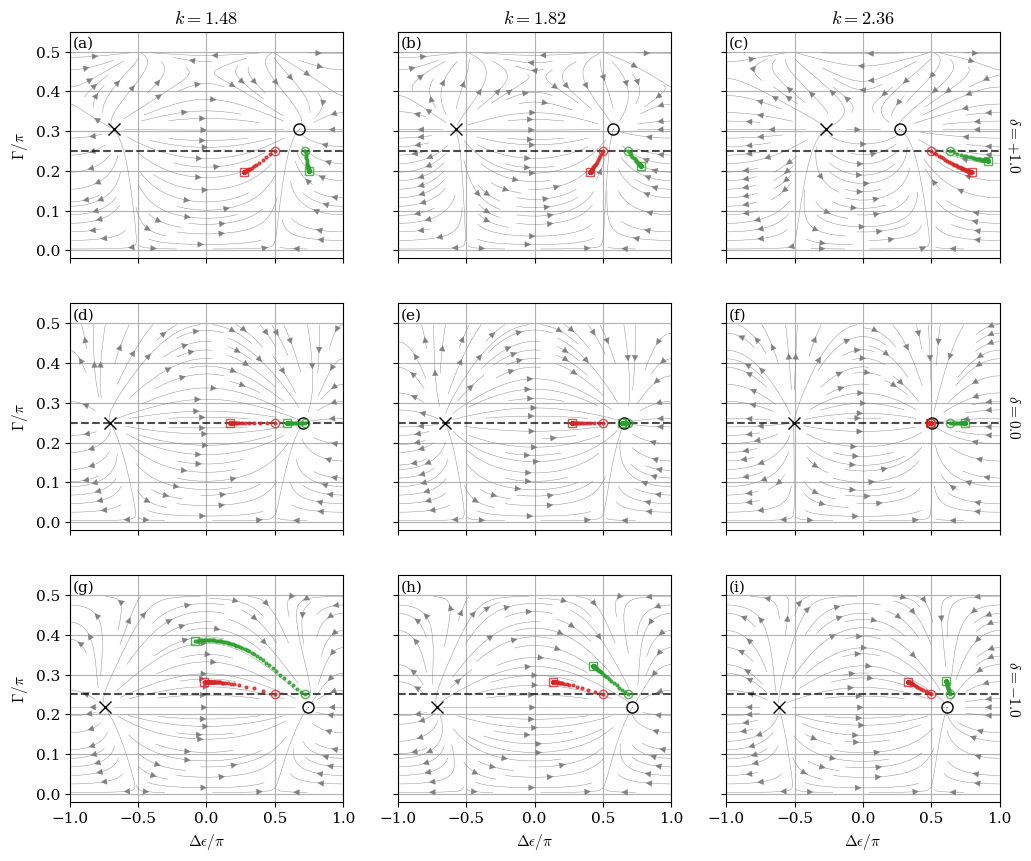

In [10]:
# phase protrait
dummy = 0
ll = 0
l = l_vec[ll]
k_vals = Sloped_k_max[:, ll]
# k_vals = [1.0, 1.5, 2.2]
T_vecs = np.linspace(1e-3, 5.0, 51)
fig, axs = plt.subplots(3,3,figsize=(12,10),sharex=True,sharey=True)

for row, delta in enumerate(delta_vec):
    for col, k in enumerate(k_vals):
        ax = axs[row, col]
        deps_grid, gamma_grid = np.meshgrid(np.linspace(-np.pi, np.pi, 101),np.linspace(0.01, np.pi/2 - 0.01, 101))
        points = np.asarray([deps_grid, gamma_grid])
        eps_dot, gamma_dot = dF(points,k,l,gamma,delta)
        ax.streamplot(deps_grid/np.pi,gamma_grid/np.pi,eps_dot,gamma_dot, color='gray', linewidth=0.3,density=0.8)
        ax.plot([-1.0, 1.0], [0.25, 0.25], 'k--', alpha=0.7)

        # Plot fixed points
        A = Phillips_A(k, l, gamma, delta)
        eigvals, eigvecs = np.linalg.eig(A)
        growth = np.max(np.real(eigvals))
        # if growth > 1e-3:
        pos_root = get_root(dF,k,l, gamma, delta, guess_init=[0.5*np.pi, 0.25*np.pi])
        neg_root = get_root(dF,k,l, gamma, delta, guess_init=[-0.5*np.pi, 0.25*np.pi])
        ax.plot(pos_root[0]/np.pi,pos_root[1]/np.pi,'ko',markersize=8,markerfacecolor='none',markeredgewidth=1)
        ax.plot(neg_root[0]/np.pi,neg_root[1]/np.pi,'kx',markersize=8,markeredgewidth=1)

        # else:
        #     pos_root = get_root(dF,k,l, gamma, delta, guess_init=[0.5*np.pi, 0.25*np.pi])
        #     neg_root = get_root(dF,k,l, gamma, delta, guess_init=[-0.5*np.pi, 0.2*np.pi])
        #     plot_root(ax, pos_root)
        #     plot_root(ax, neg_root)     

        # Plot enstrophy-optimal points
        deps0_ens, gamma0_ens = compute_optimal(T_vecs, A, np.eye(2))
        ax.plot(deps0_ens/np.pi,gamma0_ens/np.pi,'C3.', ms=4, alpha=0.8, label='Enstrophy')
        ax.plot(deps0_ens[0]/np.pi,gamma0_ens[0]/np.pi,'C3o',markerfacecolor='none',markersize=6, alpha=0.8, label=rf't={int(T_vecs[0])}')
        ax.plot(deps0_ens[-1]/np.pi,gamma0_ens[-1]/np.pi,'C3s',markerfacecolor='none',markersize=6, alpha=0.8, label=rf't={int(T_vecs[-1])}')
        
        # Plot energy-optimal points
        M = Phillips_M(k, l)
        deps0_enr, gamma0_enr = compute_optimal(T_vecs, A, M)
        ax.plot(deps0_enr/np.pi,gamma0_enr/np.pi,'C2.', ms=4, alpha=0.8, label='Energy')
        ax.plot(deps0_enr[0]/np.pi,gamma0_enr[0]/np.pi,'C2o',markerfacecolor='none',markersize=6, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[0])}$')
        ax.plot(deps0_enr[-1]/np.pi,gamma0_enr[-1]/np.pi,'C2s',markerfacecolor='none',markersize=6, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[-1])}$')

        ax.set_ylim([-0.02, 0.55])
        ax.grid()
        ax.set_title(rf'$k={k:.2f}$' if row == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$\Delta\epsilon/\pi$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$\Gamma/\pi$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

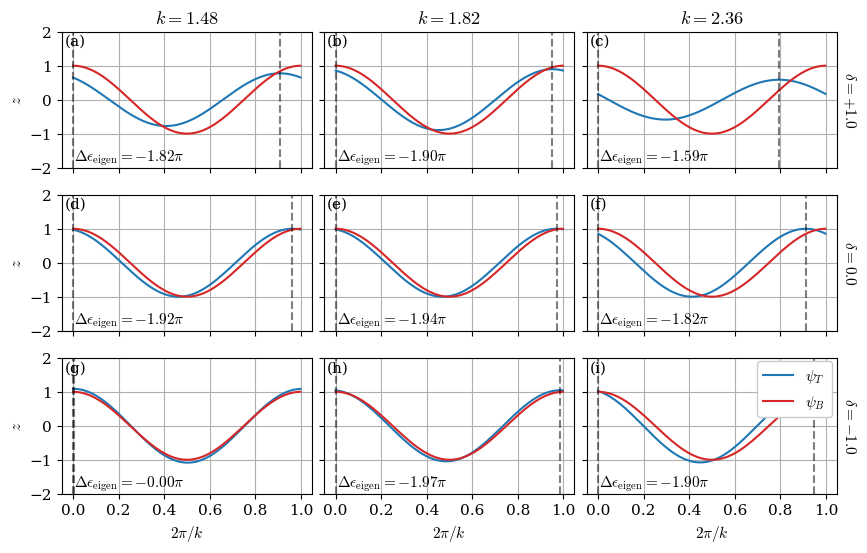

In [11]:
# streamfunction in enstrophy norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 6), sharex=True, sharey=True)
for j in [0, 1, 2]:
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Sloped_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        psi_T = Sloped_psi0_T[0, :, i, j, ll].copy()
        psi_B = Sloped_psi0_B[0, :, i, j, ll].copy()
        psi_T /= psi_B[0]
        psi_B /= psi_B[0]
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_T), 'C0', label=r'$\psi_T$')
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_B), 'C3', label=r'$\psi_B$')
        x_loc_T = x_vec[np.argmax(np.real(psi_T))] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(np.real(psi_B))] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-2.0, 2.0], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-2.0, 2.0], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.05, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={k:.2f}$" if j == 0 else "")
        ax.set_ylim(-2.0, 2.0)
        ax.grid()
        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")
    ax.xaxis.set_major_locator(MultipleLocator(0.2))

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\delta={delta_vec[idx]:+.1f}$" if delta_vec[idx] != 0 else r"$\delta=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
axs[-1,-1].legend(loc='upper right' ,bbox_to_anchor=(1.01, 1.03), framealpha=1.0)
fig.subplots_adjust(wspace=0.05)

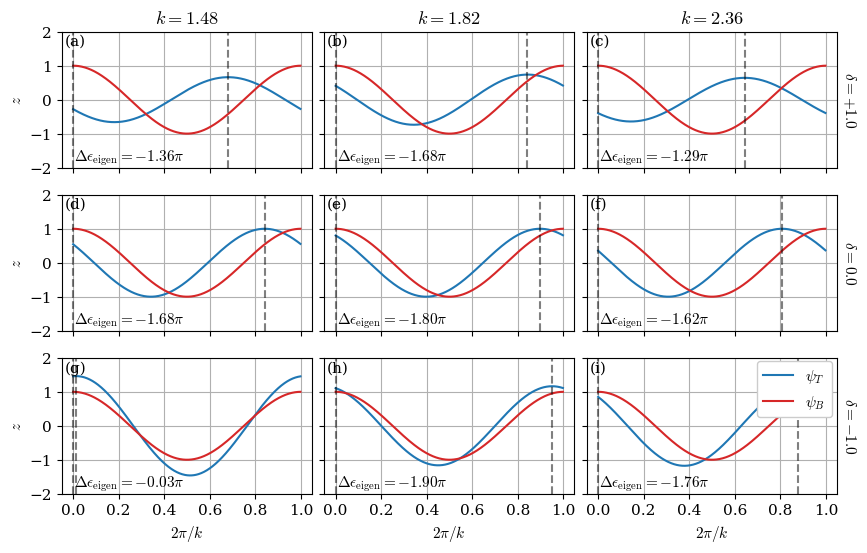

In [12]:
# streamfunction in energy norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 6), sharex=True, sharey=True)
for j in [0, 1, 2]:
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Sloped_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        psi_T = Sloped_psi0_T_enr[0, :, i, j, ll].copy()
        psi_B = Sloped_psi0_B_enr[0, :, i, j, ll].copy()
        psi_T /= psi_B[0]
        psi_B /= psi_B[0]
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_T), 'C0', label=r'$\psi_T$')
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_B), 'C3', label=r'$\psi_B$')
        x_loc_T = x_vec[np.argmax(np.real(psi_T))] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(np.real(psi_B))] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-2.0, 2.0], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-2.0, 2.0], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.05, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={k:.2f}$" if j == 0 else "")
        ax.set_ylim(-2.0, 2.0)
        ax.grid()
        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")
    ax.xaxis.set_major_locator(MultipleLocator(0.2))

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\delta={delta_vec[idx]:+.1f}$" if delta_vec[idx] != 0 else r"$\delta=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
axs[-1,-1].legend(loc='upper right' ,bbox_to_anchor=(1.01, 1.03), framealpha=1.0)
fig.subplots_adjust(wspace=0.05)

l = 0.0
  ens min at k = 2.063, matrix norm = 1.7881e+00
  enr min at k = 1.660, matrix norm = 3.4762e+00
  ens min at k = 2.375, matrix norm = 3.1623e-02
  enr min at k = 1.998, matrix norm = 1.5087e-02
  ens min at k = 2.739, matrix norm = 1.0168e+00
  enr min at k = 2.479, matrix norm = 1.3921e+00


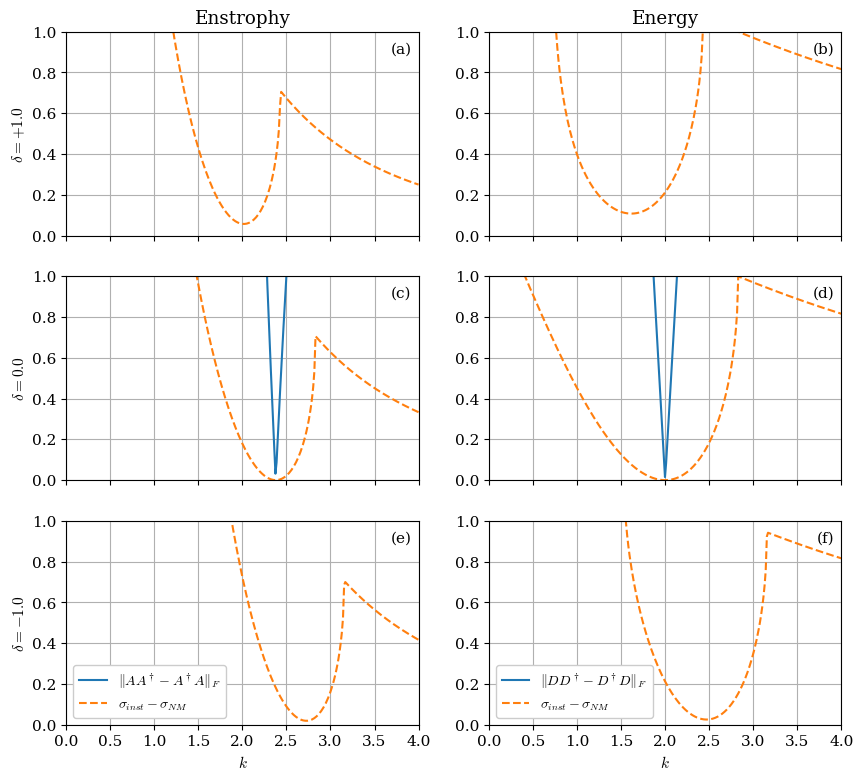

In [13]:
# normality
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
ll = 0
for j in range(3):
    ax = axs[j, 0]
    ax.plot(k_vec, normality[:, j, ll], label=r'$\|AA^\dagger-A^\dagger A\|_F$')
    diff = np.abs(Sloped_growth_ens[:, j, ll] - Sloped_growth_NM[:, j, ll])
    ax.plot(k_vec, diff,'--', label=r'$\sigma_{inst}-\sigma_{NM}$')
    ax.set_title('Enstrophy' if j == 0 else "")
    ax.set_ylim(0.0, 1.0)
    ax.text(0.98, 0.95, f"({letters[2*j]})", transform=ax.transAxes, ha='right', va='top')
    ax.set_ylabel(rf'$\delta={delta_vec[j]:+.1f}$' if delta_vec[j] != 0 else r'$\delta=0.0$', rotation=90)
    
    ax = axs[j, 1]
    ax.plot(k_vec, normality_enr[:, j, ll], label=r'$\|DD^\dagger-D^\dagger D\|_F$')
    diff = np.abs(Sloped_growth_enr[:, j, ll] - Sloped_growth_NM[:, j, ll])
    ax.plot(k_vec, diff,'--', label=r'$\sigma_{inst}-\sigma_{NM}$')
    ax.set_title('Energy' if j == 0 else "")
    ax.set_ylim(0.0, 1.0)
    ax.text(0.98, 0.95, f"({letters[2*j+1]})", transform=ax.transAxes, ha='right', va='top')  

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 4)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")
    ax.legend(loc='lower left', framealpha=1.0, fontsize=10.0)

print(f"l = {l_vec[0]}")
for j in range(3):
    dum = normality[:, j, ll]
    print(f"  ens min at k = {k_vec[np.where(dum == np.min(dum))].item():.3f}, matrix norm = {np.min(dum):.4e}")
    dum = normality_enr[:, j, ll]
    print(f"  enr min at k = {k_vec[np.where(dum == np.min(dum))].item():.3f}, matrix norm = {np.min(dum):.4e}")

## 2) Dependence on $\beta$-plane: $\delta=0$, varying $\gamma$.  

In [14]:
# compute growth rate, phase shift and amplitude ratio for NM and instantaneous in enstrophy and energy
# k_vec = np.linspace(1e-3, 4, 501)
k_vec = np.concat([10 ** np.linspace(-3, -1, 201), np.linspace(1e-1, 4, 301)])
gamma_vec = [0.0, 1.0, 1.5]
l_vec = [0.0, 1.0]
# l = 0
delta = 0.0

Phillips_growth_NM = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_eps_NM = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_Gamma_NM = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_growth_ens = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_eps_ens = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_Gamma_ens = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_growth_enr = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_eps_enr = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_Gamma_enr = np.zeros((len(k_vec), len(gamma_vec), 2))
Phillips_Delta_max = np.zeros((len(k_vec), len(gamma_vec), 2))
normality = np.zeros((len(k_vec), len(gamma_vec), 2))
normality_enr = np.zeros((len(k_vec), len(gamma_vec), 2))

for ll, l in enumerate(l_vec):
    for j, gamma in enumerate(gamma_vec):
        for i, k in enumerate(k_vec):
            A = Phillips_A(k, l, gamma, delta)
            M = Phillips_M(k, l)
            eigvals, eigvecs = eig(A)
            idx = np.argmax(np.real(eigvals))
            Phillips_growth_NM[i, j, ll] = np.real(eigvals[idx])
            if Phillips_growth_NM[i, j, ll]>1e-4:
                q = eigvecs[:, idx]
            else:
                id = np.argmax(np.imag(eigvals))
                q = eigvecs[:, id]
            Phillips_eps_NM[i, j, ll], Phillips_Gamma_NM[i, j, ll] = np.arccos(np.cos(np.angle(q[0]/q[-1]))), np.arctan(np.abs(q[0]/q[-1]))

            growth, q = instantaneous(A, np.eye(2))
            Phillips_growth_ens[i, j, ll] = np.real(growth)
            Phillips_eps_ens[i, j, ll], Phillips_Gamma_ens[i, j, ll] = state_to_phase(q)

            growth, q = instantaneous(A, M)
            Phillips_growth_enr[i, j, ll] = np.real(growth)
            Phillips_eps_enr[i, j, ll], Phillips_Gamma_enr[i, j, ll] = state_to_phase(q)

            commutator = A @ A.conj().T - A.conj().T @ A
            normality[i, j, ll] = np.linalg.norm(commutator)

            T = sqrtm(M)
            D = T @ A @ np.linalg.inv(T)
            commutator = D @ D.conj().T - D.conj().T @ D
            normality_enr[i, j, ll] = np.linalg.norm(commutator)

In [15]:
# compute NM growth k_max for diff. delta
Phillips_k_max = np.zeros((len(gamma_vec), 2))
for ll in range(len(l_vec)):
    for j in range(len(gamma_vec)):
        k_max_idx = np.argmax(Phillips_growth_NM[:, j, ll])
        Phillips_k_max[j, ll] = k_vec[k_max_idx]
        print(rf'gamma={gamma_vec[j]}, l={l_vec[ll]}, k_max={Phillips_k_max[j, ll]}')

gamma=0.0, l=0.0, k_max=1.816
gamma=1.0, l=0.0, k_max=2.076
gamma=1.5, l=0.0, k_max=2.232
gamma=0.0, l=1.0, k_max=1.738
gamma=1.0, l=1.0, k_max=1.894
gamma=1.5, l=1.0, k_max=2.024


In [16]:
# compute effective optimal growth in enstrophy and energy norm for selected target time
# t_vals = np.linspace(0.0, 5.0, 201)
t_vals = [1.0, 3.0, 5.0]
# l = 0.0

Phillips_effective_ens = np.zeros((len(k_vec), len(gamma_vec), len(t_vals), 2))
Phillips_effective_enr = np.zeros((len(k_vec), len(gamma_vec), len(t_vals), 2))

for ll, l in enumerate(l_vec):
    for j, gamma in enumerate(gamma_vec):
        for i, k in enumerate(k_vec):
            A = Phillips_A(k, l, gamma, delta)
            M = Phillips_M(k, l)
            for d, t in enumerate(t_vals):
                amp_ens, _, _ = finite_time_optimal(t, A, np.eye(2)) # Euclidean norm growth
                amp_enr, _, _ = finite_time_optimal(t, A, M) # Energy norm growth
                Phillips_effective_ens[i, j, d, ll] = np.log(amp_ens)/t
                Phillips_effective_enr[i, j, d, ll] = np.log(amp_enr)/t

In [17]:
# compute streamfunction of optimal perturbation at selected target time in enstrophy and energy norm
z_vec = np.linspace(-1, 1, 31)
t = 5.0
psi0_B = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
psi0_T = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
# psit_B = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
# psit_T = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
psi0_B_enr = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
psi0_T_enr = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
# psit_B_enr = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
# psit_T_enr = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)

for ll, l in enumerate(l_vec):
    for j, idx in enumerate([0, 1, 2]):
        gamma = gamma_vec[idx]
        for i, k_idx in enumerate([0, 1, 2]):
            k = Phillips_k_max[k_idx, ll]
            K2 = k**2 + l**2
            x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
            A = Phillips_A(k, l, gamma, delta)
            M = Phillips_M(k, l)
            _, q0, qt = finite_time_optimal(t, A, np.eye(2))
            _, q0_enr, qt_enr = finite_time_optimal(t, A, M)

            q0[0] /= q0[1]
            qt[0] /= qt[1]
            q0[1] = 1.0
            qt[1] = 1.0
            q0_enr[0] /= q0_enr[1]
            qt_enr[0] /= qt_enr[1]
            q0_enr[1] = 1.0
            qt_enr[1] = 1.0

            Z = z_vec[:, None]
            X = x_vec[None, :]
            psi0_T[:, :, i, j, ll] = - np.exp(zi * k * X) * ((1 + 4 / K2) * q0[0] + (4 / K2) * q0[1]) / (K2 + 8)
            psi0_B[:, :, i, j, ll] = - np.exp(zi * k * X) * ((4 / K2) * q0[0] + (1 + 4 / K2) * q0[1]) / (K2 + 8)

            # psit_B[:, :, i, j] = np.exp(zi * k * X) * (-qt[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
            # psit_T[:, :, i, j] = np.exp(zi * k * X) * (-qt[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

            psi0_T_enr[:, :, i, j, ll] = - np.exp(zi * k * X) * ((1 + 4 / (K2)) * q0_enr[0] + (4 / K2) * q0_enr[1]) / (K2 + 8)
            psi0_B_enr[:, :, i, j, ll] = - np.exp(zi * k * X) * ((4 / K2) * q0_enr[0] + (1 + 4 / K2) * q0_enr[1]) / (K2 + 8)

            # psit_B_enr[:, :, i, j] = np.exp(zi * k * X) * (-qt_enr[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
            # psit_T_enr[:, :, i, j] = np.exp(zi * k * X) * (-qt_enr[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

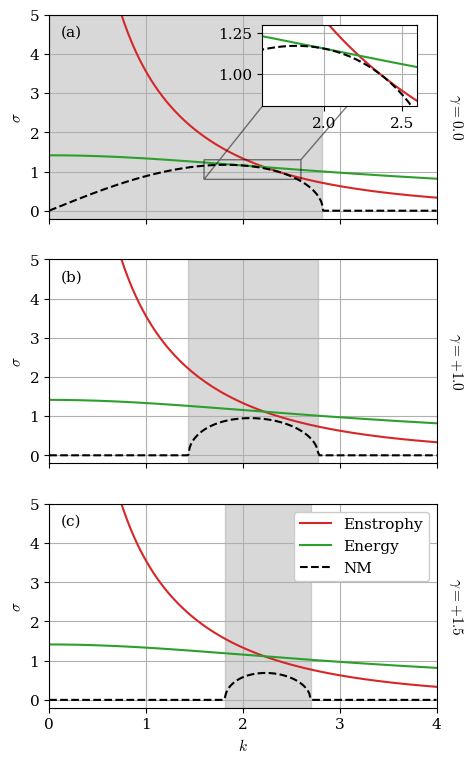

In [18]:
# growth rate
fig, axs = plt.subplots(3, 1, figsize=(5, 9), sharex=True)
ll = 0
for j, ax in enumerate(axs):
    ax.plot(k_vec, Phillips_growth_ens[:, j, ll],'C3', label='Enstrophy')
    ax.plot(k_vec, Phillips_growth_enr[:, j, ll],'C2', label='Energy')
    ax.plot(k_vec, Phillips_growth_NM[:, j, ll], 'k--', label='NM')
    ax.set_xlim(0, 4)
    ax.set_ylim(-0.2, 5.0)
    ax.set_ylabel(r"$\sigma$")
    k_shade_ind = np.where(Phillips_growth_NM[:, j, ll] > 1e-3)[0]
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.grid()
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.text(0.03, 0.95, f"({letters[j]})", transform=ax.transAxes, ha='left', va='top')

    if j == 0:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Phillips_growth_ens[:, j, ll],'C3')
        ax_inset.plot(k_vec, Phillips_growth_enr[:, j, ll],'C2')
        ax_inset.plot(k_vec, Phillips_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(1.6, 2.6)
        ax_inset.set_ylim(0.8, 1.3)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")

for row, ax in enumerate(axs):
    ax.text(1.05, 0.5, rf'$\gamma={gamma_vec[row]:+.1f}$' if gamma_vec[row] != 0 else r'$\gamma=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1].set_xlabel(r"$k$")
axs[-1].legend(loc='upper right', framealpha=1.0)

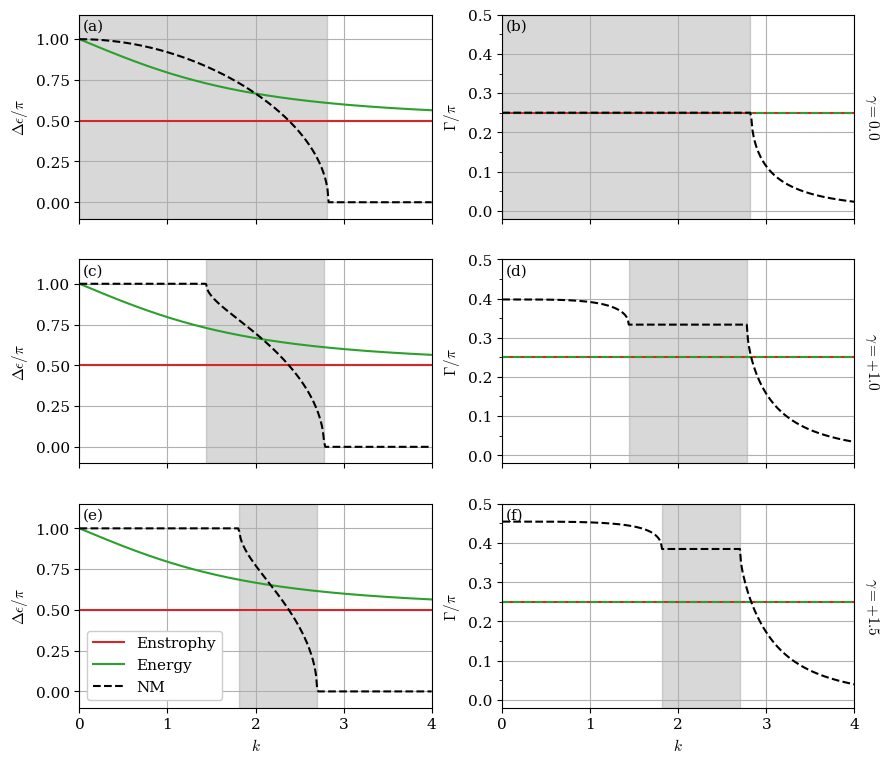

In [19]:
# CRW quantities
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
ll = 0
for j in range(3):
    k_shade_ind = np.where(Phillips_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    ax.plot(k_vec, Phillips_eps_ens[:, j, ll]/np.pi, 'C3', label='Enstrophy')
    ax.plot(k_vec, Phillips_eps_enr[:, j, ll]/np.pi, 'C2', label='Energy')
    ax.plot(k_vec, Phillips_eps_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylim([-0.1, 1.15])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylabel(r'$\Delta\epsilon/\pi$')
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    
    ax = axs[j, 1]
    ax.plot(k_vec, Phillips_Gamma_ens[:, j, ll]/np.pi, 'C3', label='Enstrophy')
    ax.plot(k_vec, Phillips_Gamma_enr[:, j, ll]/np.pi, 'C2--', label='Energy')
    ax.plot(k_vec, Phillips_Gamma_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylim(-0.02, 0.5)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.set_ylabel(r'$\Gamma/\pi$')
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top')  

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 4)
    ax.xaxis.set_major_locator(MultipleLocator(1.0))


for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\gamma={gamma_vec[row]:+.1f}$' if gamma_vec[row] != 0 else r'$\gamma=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1,0].legend(loc='lower left', framealpha=1.0)

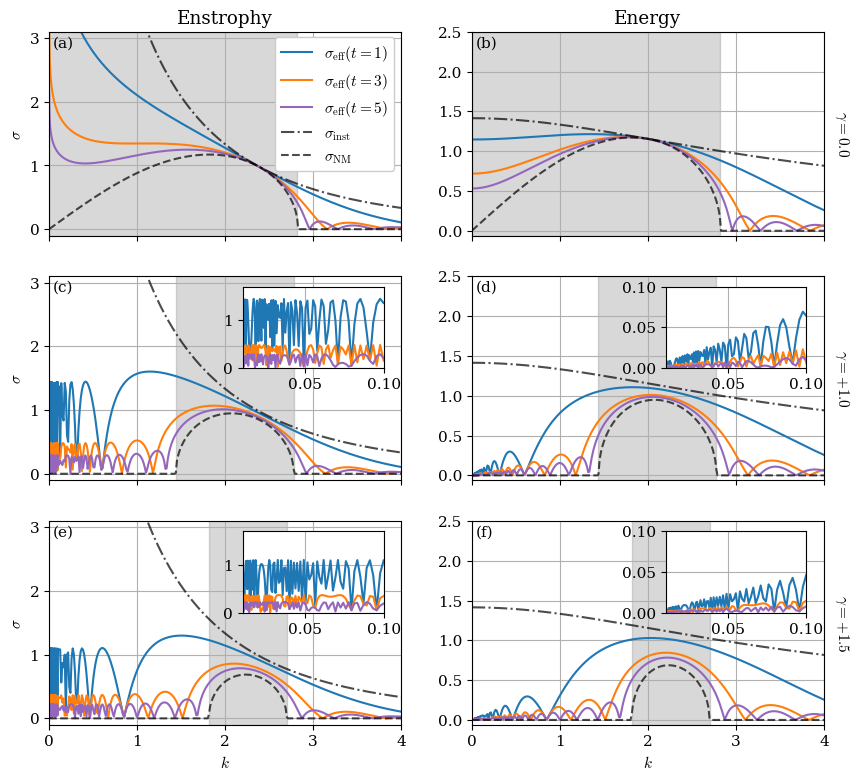

In [20]:
# effective optimal growth rate
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
colors = ['C0', 'C1', 'C4']
ll = 0
for j in range(3):
    k_shade_ind = np.where(Phillips_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Phillips_effective_ens[:, j, d, ll], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Phillips_growth_ens[:, j, ll], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Phillips_growth_NM[:, j, ll], 'k--', alpha=0.7, label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Enstrophy' if j == 0 else "")
    ax.set_ylim(-0.1, 3.1)
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    ax.set_ylabel(r"$\sigma$")

    if j != 0:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        for d, t in enumerate(t_vals):
            ax_inset.plot(k_vec, Phillips_effective_ens[:, j, d, ll], color=colors[d])
        
        ax_inset.set_xlim(1e-2, 1e-1)
        ax_inset.set_ylim(0.0, 1.7)
        ax_inset.grid()
    
    ax = axs[j, 1]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Phillips_effective_enr[:, j, d, ll], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Phillips_growth_enr[:, j, ll], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Phillips_growth_NM[:, j, ll], 'k--', alpha=0.7, label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Energy' if j == 0 else "")
    ax.set_ylim(-0.06, 2.5)
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top') 

    if j != 0:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        for d, t in enumerate(t_vals):
            ax_inset.plot(k_vec, Phillips_effective_enr[:, j, d, ll], color=colors[d])
        
        ax_inset.set_xlim(1e-2, 1e-1)
        ax_inset.set_ylim(0.0, 0.1)
        ax_inset.grid()

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 4)
    ax.xaxis.set_major_locator(MultipleLocator(1.0))

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\gamma={gamma_vec[row]:+.1f}$' if gamma_vec[row] != 0 else r'$\gamma=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

axs[0,0].legend(loc='upper right' ,bbox_to_anchor=(1.0, 1.01), framealpha=1.0)

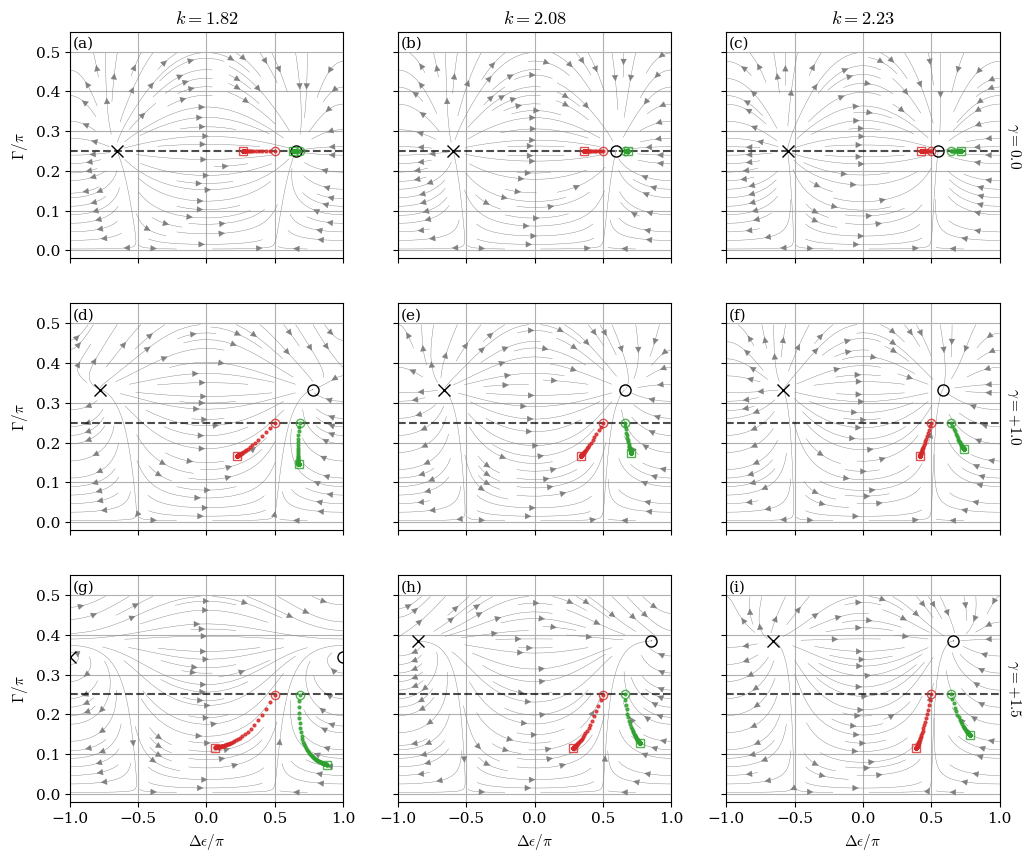

In [21]:
# phase protrait
dummy = 0
ll = 0
l = l_vec[ll]
k_vals = Phillips_k_max[:, ll]
# k_vals = [1.0, 1.5, 2.2]
T_vecs = np.linspace(1e-3, 5.0, 51)
fig, axs = plt.subplots(3,3,figsize=(12,10),sharex=True,sharey=True)

for row, gamma in enumerate(gamma_vec):
    for col, k in enumerate(k_vals):
        ax = axs[row, col]
        deps_grid, gamma_grid = np.meshgrid(np.linspace(-np.pi, np.pi, 101),np.linspace(0.01, np.pi/2 - 0.01, 101))
        points = np.asarray([deps_grid, gamma_grid])
        eps_dot, gamma_dot = dF(points,k,l,gamma,delta)
        ax.streamplot(deps_grid/np.pi,gamma_grid/np.pi,eps_dot,gamma_dot, color='gray', linewidth=0.3,density=0.8)
        ax.plot([-1.0, 1.0], [0.25, 0.25], 'k--', alpha=0.7)

        # Plot fixed points
        A = Phillips_A(k, l, gamma, delta)
        eigvals, eigvecs = np.linalg.eig(A)
        growth = np.max(np.real(eigvals))
        if growth > 1e-3:
            pos_root = get_root(dF,k,l, gamma, delta, guess_init=[0.5*np.pi, 0.25*np.pi])
            neg_root = get_root(dF,k,l, gamma, delta, guess_init=[-0.5*np.pi, 0.25*np.pi])
            ax.plot(pos_root[0]/np.pi,pos_root[1]/np.pi,'ko',markersize=8,markerfacecolor='none',markeredgewidth=1)
            ax.plot(neg_root[0]/np.pi,neg_root[1]/np.pi,'kx',markersize=8,markeredgewidth=1)

        else:
            pos_root = get_root(dF,k,l, gamma, delta, guess_init=[0.5*np.pi, 0.25*np.pi])
            neg_root = get_root(dF,k,l, gamma, delta, guess_init=[-0.5*np.pi, 0.2*np.pi])
            plot_root(ax, pos_root)
            plot_root(ax, neg_root)     

        # Plot enstrophy-optimal points
        deps0_ens, gamma0_ens = compute_optimal(T_vecs, A, np.eye(2))
        ax.plot(deps0_ens/np.pi,gamma0_ens/np.pi,'C3.', ms=4, alpha=0.8, label='Enstrophy')
        ax.plot(deps0_ens[0]/np.pi,gamma0_ens[0]/np.pi,'C3o',markerfacecolor='none',markersize=6, alpha=0.8, label=rf't={int(T_vecs[0])}')
        ax.plot(deps0_ens[-1]/np.pi,gamma0_ens[-1]/np.pi,'C3s',markerfacecolor='none',markersize=6, alpha=0.8, label=rf't={int(T_vecs[-1])}')
        
        # Plot energy-optimal points
        M = Phillips_M(k, l)
        deps0_enr, gamma0_enr = compute_optimal(T_vecs, A, M)
        ax.plot(deps0_enr/np.pi,gamma0_enr/np.pi,'C2.', ms=4, alpha=0.8, label='Energy')
        ax.plot(deps0_enr[0]/np.pi,gamma0_enr[0]/np.pi,'C2o',markerfacecolor='none',markersize=6, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[0])}$')
        ax.plot(deps0_enr[-1]/np.pi,gamma0_enr[-1]/np.pi,'C2s',markerfacecolor='none',markersize=6, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[-1])}$')

        ax.set_ylim([-0.02, 0.55])
        ax.grid()
        ax.set_title(rf'$k={k:.2f}$' if row == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$\Delta\epsilon/\pi$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$\Gamma/\pi$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\gamma={gamma_vec[row]:+.1f}$' if gamma_vec[row] != 0 else r'$\gamma=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

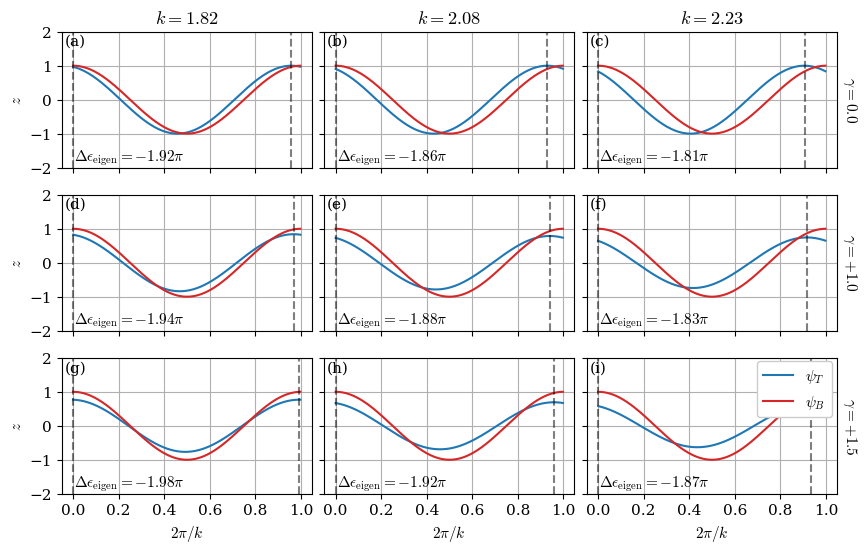

In [22]:
# streamfunction in enstrophy norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 6), sharex=True, sharey=True)
for j in [0, 1, 2]:
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Phillips_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        psi_T = psi0_T[0, :, i, j, ll].copy()
        psi_B = psi0_B[0, :, i, j, ll].copy()
        psi_T /= psi_B[0]
        psi_B /= psi_B[0]
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_T), 'C0', label=r'$\psi_T$')
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_B), 'C3', label=r'$\psi_B$')
        x_loc_T = x_vec[np.argmax(np.real(psi_T))] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(np.real(psi_B))] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-2.0, 2.0], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-2.0, 2.0], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.05, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={k:.2f}$" if j == 0 else "")
        ax.set_ylim(-2.0, 2.0)
        ax.grid()
        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")
    ax.xaxis.set_major_locator(MultipleLocator(0.2))

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\gamma={gamma_vec[idx]:+.1f}$" if gamma_vec[idx] != 0 else r"$\gamma=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
axs[-1,-1].legend(loc='upper right' ,bbox_to_anchor=(1.01, 1.03), framealpha=1.0)
fig.subplots_adjust(wspace=0.05)

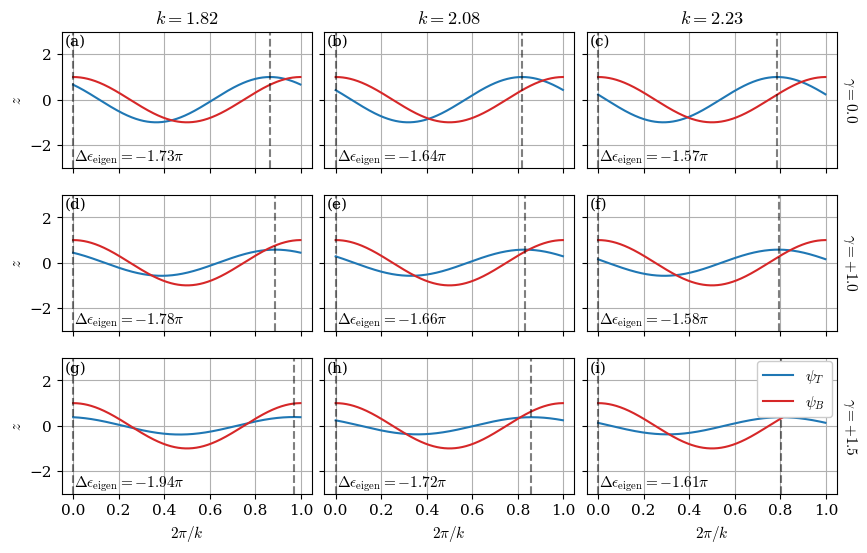

In [23]:
# streamfunction in energy norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 6), sharex=True, sharey=True)
for j in [0, 1, 2]:
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Phillips_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        psi_T = psi0_T_enr[0, :, i, j, ll].copy()
        psi_B = psi0_B_enr[0, :, i, j, ll].copy()
        psi_T /= psi_B[0]
        psi_B /= psi_B[0]
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_T), 'C0', label=r'$\psi_T$')
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_B), 'C3', label=r'$\psi_B$')
        x_loc_T = x_vec[np.argmax(np.real(psi_T))] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(np.real(psi_B))] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-3.0, 3.0], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-3.0, 3.0], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.05, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={k:.2f}$" if j == 0 else "")
        ax.set_ylim(-3.0, 3.0)
        ax.grid()
        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")
    ax.xaxis.set_major_locator(MultipleLocator(0.2))

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\gamma={gamma_vec[idx]:+.1f}$" if gamma_vec[idx] != 0 else r"$\gamma=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
axs[-1,-1].legend(loc='upper right' ,bbox_to_anchor=(1.01, 1.03), framealpha=1.0)
fig.subplots_adjust(wspace=0.05)
# fig.savefig('figure/figure6.pdf', bbox_inches='tight')

## 3) Looking at the KE norm instead

In [24]:
def Phillips_KE(k, l):   #Kinetic energy matrix for Phillips
    K2 = k**2 + l**2

    Linvt = -1 / (K2 + 8) * np.array([
        [1 + 4 / K2, 4 / K2],
        [4 / K2, 1 + 4 / K2]
    ])

    Mpsi = np.array([
        [K2, 0],
        [0, K2]
    ])

    Mq = Linvt.T @ Mpsi @ Linvt
    return Mq

def Phillips_PE(k, l):   # Potential energy matrix
    K2 = k**2 + l**2

    Linvt = -1 / (K2 + 8) * np.array([
        [1 + 4 / K2, 4 / K2],
        [4 / K2, 1 + 4 / K2]
    ])

    Mpsi = 4 * np.array([
        [1, -1],
        [-1, 1]
    ])

    Mq = Linvt.T @ Mpsi @ Linvt
    return Mq

In [25]:
# compute growth rate, phase shift and amplitude ratio for other norms
# k_vec = np.linspace(1e-3, 2, 301)
k_vec = np.concat([10 ** np.linspace(-3, -1, 201), np.linspace(1e-1, 4, 301)])
gamma_vec = [0.0, 1.0, 1.5]
# l = 0
# Bu = 1.0
ll = 0
delta = 0
Phillips_growth_ke = np.zeros((len(k_vec), len(gamma_vec)))
Phillips_eps_ke = np.zeros((len(k_vec), len(gamma_vec)))
Phillips_Gamma_ke = np.zeros((len(k_vec), len(gamma_vec)))
Phillips_growth_pe = np.zeros((len(k_vec), len(gamma_vec)))
Phillips_eps_pe = np.zeros((len(k_vec), len(gamma_vec)))
Phillips_Gamma_pe = np.zeros((len(k_vec), len(gamma_vec)))

for j, gamma in enumerate(gamma_vec):
    for i, k in enumerate(k_vec):
        A = Phillips_A(k, l, gamma, delta)
        K = Phillips_KE(k, l)    # kinetic energy
        PE = Phillips_PE(k, l)  # potential energy
        eigvals, eigvecs = eig(A)
        idx = np.argmax(np.real(eigvals))
        if Phillips_growth_NM[i, j, ll]>1e-4:
            q = eigvecs[:, idx]
        else:
            id = np.argmax(np.imag(eigvals))
            q = eigvecs[:, id]

        growth, q = instantaneous(A, K)
        Phillips_growth_ke[i, j] = np.real(growth)
        Phillips_eps_ke[i, j], Phillips_Gamma_ke[i, j] = state_to_phase(q)

        # growth, q = instantaneous(A, PE)
        # Phillips_growth_pe[i, j] = np.real(growth)
        # Phillips_eps_pe[i, j], Phillips_Gamma_pe[i, j] = state_to_phase(q)

In [26]:
# effective optimal growth
t_vals = [1.0, 3.0, 5.0]
l = 0.0

Phillips_effective_ke = np.zeros((len(k_vec), len(gamma_vec), len(t_vals)))
Phillips_effective_pe = np.zeros((len(k_vec), len(gamma_vec), len(t_vals)))

for j, gamma in enumerate(gamma_vec):
    for i, k in enumerate(k_vec):
        A = Phillips_A(k, l, gamma, delta)
        K = Phillips_KE(k, l)
        # PE = Phillips_PE(k, l)
        for d, t in enumerate(t_vals):
            amp_ke, _, _ = finite_time_optimal(t, A, K)
            # amp_pe, _, _ = finite_time_optimal(t, A, PE)
            Phillips_effective_ke[i, j, d] = np.log(amp_ke)/t
            # Phillips_effective_pe[i, j, d] = np.log(amp_pe)/t

In [27]:
# z_vec = np.linspace(-1, 1, 31)
t = 5.0
psi0_B_ke = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)
psi0_T_ke = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)
psi0_B_pe = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)
psi0_T_pe = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)

for j, idx in enumerate([0, 1, 2]):
    gamma = gamma_vec[idx]
    for i, k_idx in enumerate([0, 1, 2]):
        k = Phillips_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        A = Phillips_A(k, l, gamma, delta)
        K = Phillips_KE(k, l)
        # PE = Phillips_PE(k, l)
        _, q0_ke, _ = finite_time_optimal(t, A, K)
        # _, q0_pe, _ = finite_time_optimal(t, A, PE)

        q0_ke[0] /= q0_ke[1]
        q0_ke[1] = 1.0
        # q0_pe[0] /= q0_pe[1]
        # q0_pe[1] = 1.0

        Z = z_vec[:, None]
        X = x_vec[None, :]
        psi0_T_ke[:, :, i, j] = - np.exp(zi * k * X) * ((1 + 4 / K2) * q0_ke[0] + 4 / K2 * q0_ke[1]) / (K2 + 8)
        psi0_B_ke[:, :, i, j] = - np.exp(zi * k * X) * ( 4 / K2 * q0_ke[0] + (1 + 4 / K2) * q0_ke[1]) / (K2 + 8)

        # psi0_B_pe[:, :, i, j] = - np.exp(zi * k * X) * ((1 + 4 / K2) * q0_pe[0] + 4 / K2 * q0_pe[1]) / (K2 + 8)
        # psi0_T_pe[:, :, i, j] = - np.exp(zi * k * X) * ( 4 / K2 * q0_pe[0] + (1 + 4 / K2) * q0_pe[1]) / (K2 + 8)


field0_ke = psi0_T_ke + psi0_B_ke
diff0_ke = np.angle(field0_ke[-1, 0, :, :]/field0_ke[0, 0, :, :])
# field0_pe = psi0_T_pe + psi0_B_pe
# diff0_pe = np.angle(field0_pe[-1, 0, :, :]/field0_pe[0, 0, :, :])

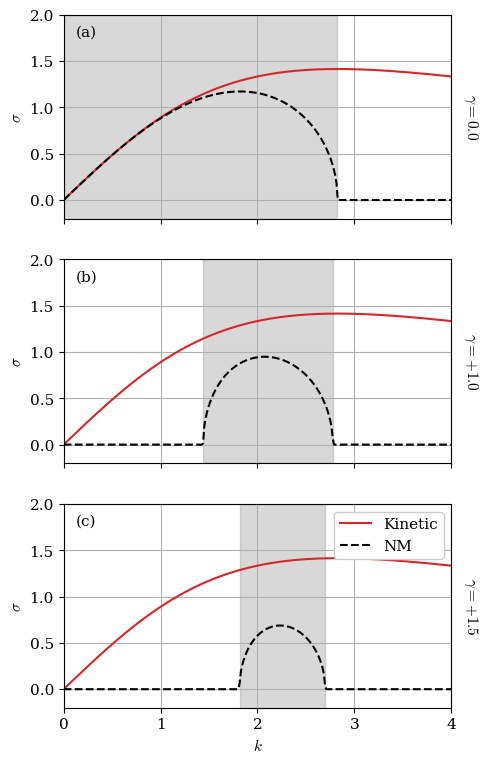

In [28]:
# growth rate
fig, axs = plt.subplots(3, 1, figsize=(5, 9), sharex=True)
ll = 0
for j, ax in enumerate(axs):
    ax.plot(k_vec, Phillips_growth_ke[:, j],'C3', label='Kinetic')
    ax.plot(k_vec, Phillips_growth_NM[:, j, ll], 'k--', label='NM')
    ax.set_xlim(0, 4)
    ax.set_ylim(-0.2, 2.0)
    ax.set_ylabel(r"$\sigma$")
    k_shade_ind = np.where(Phillips_growth_NM[:, j, ll] > 1e-3)[0]
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.grid()
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.text(0.03, 0.95, f"({letters[j]})", transform=ax.transAxes, ha='left', va='top')


for row, ax in enumerate(axs):
    ax.text(1.05, 0.5, rf'$\gamma={gamma_vec[row]:+.1f}$' if gamma_vec[row] != 0 else r'$\gamma=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1].set_xlabel(r"$k$")
axs[-1].legend(loc='upper right', framealpha=1.0)

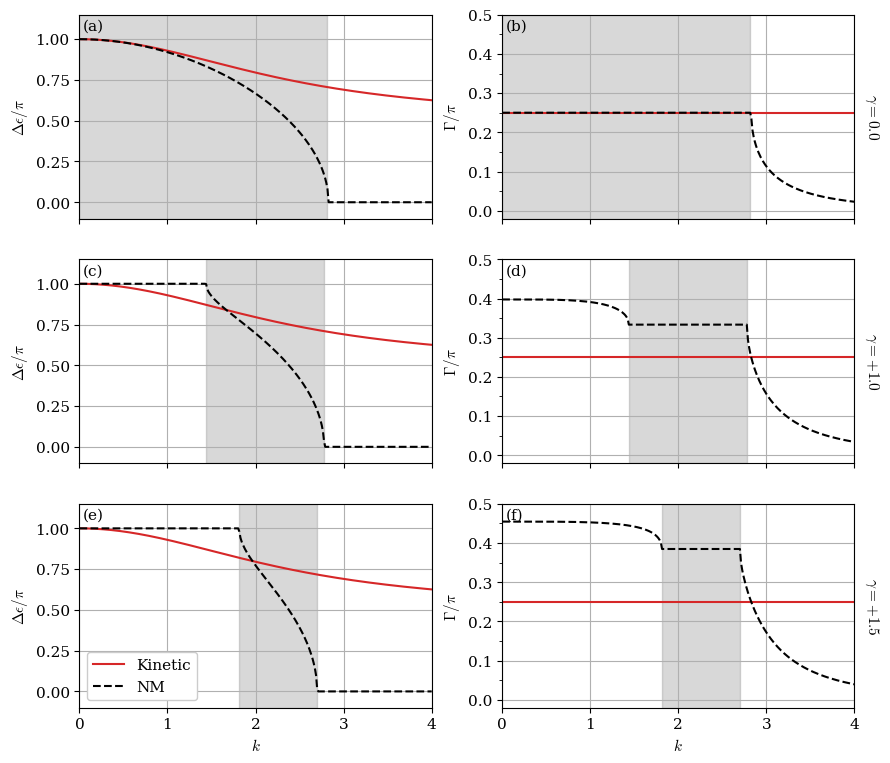

In [29]:
# CRW quantities
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
ll = 0
for j in range(3):
    k_shade_ind = np.where(Phillips_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    ax.plot(k_vec, Phillips_eps_ke[:, j]/np.pi, 'C3', label='Kinetic')
    ax.plot(k_vec, Phillips_eps_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylim([-0.1, 1.15])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylabel(r'$\Delta\epsilon/\pi$')
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    
    ax = axs[j, 1]
    ax.plot(k_vec, Phillips_Gamma_ke[:, j]/np.pi, 'C3', label='Kinetic')
    ax.plot(k_vec, Phillips_Gamma_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylim(-0.02, 0.5)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.set_ylabel(r'$\Gamma/\pi$')
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top')  

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 4)
    ax.xaxis.set_major_locator(MultipleLocator(1.0))


for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\gamma={gamma_vec[row]:+.1f}$' if gamma_vec[row] != 0 else r'$\gamma=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1,0].legend(loc='lower left', framealpha=1.0)

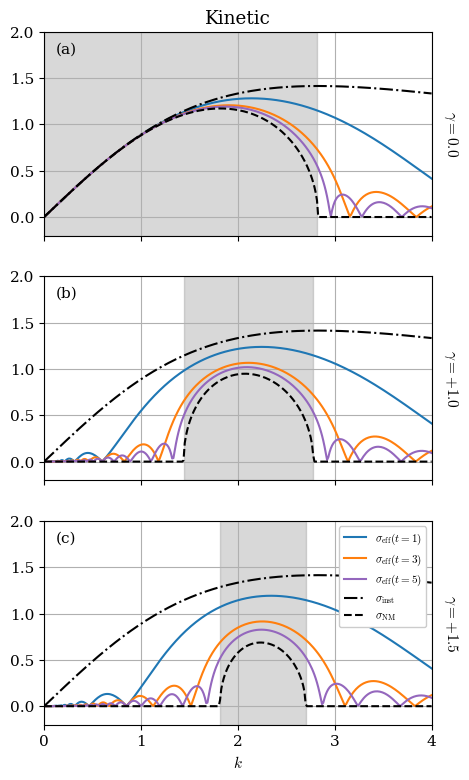

In [30]:
# growth rate
fig, axs = plt.subplots(3, 1, figsize=(5, 9), sharex=True)
ll = 0
for j, ax in enumerate(axs):
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Phillips_effective_ke[:, j, d], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Phillips_growth_ke[:, j],'k-.', label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Phillips_growth_NM[:, j, ll], 'k--', label=r'$\sigma_{\rm NM}$')
    ax.set_title('Kinetic' if j == 0 else "")
    ax.set_xlim(0, 4)
    ax.set_ylim(-0.2, 2.0)
    # ax.set_ylabel(r"$\sigma$")
    k_shade_ind = np.where(Phillips_growth_NM[:, j, ll] > 1e-3)[0]
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.grid()
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.text(0.03, 0.95, f"({letters[j]})", transform=ax.transAxes, ha='left', va='top')


for row, ax in enumerate(axs):
    ax.text(1.05, 0.5, rf'$\gamma={gamma_vec[row]:+.1f}$' if gamma_vec[row] != 0 else r'$\gamma=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1].set_xlabel(r"$k$")
axs[-1].legend(loc='upper right', framealpha=1.0, fontsize=8)

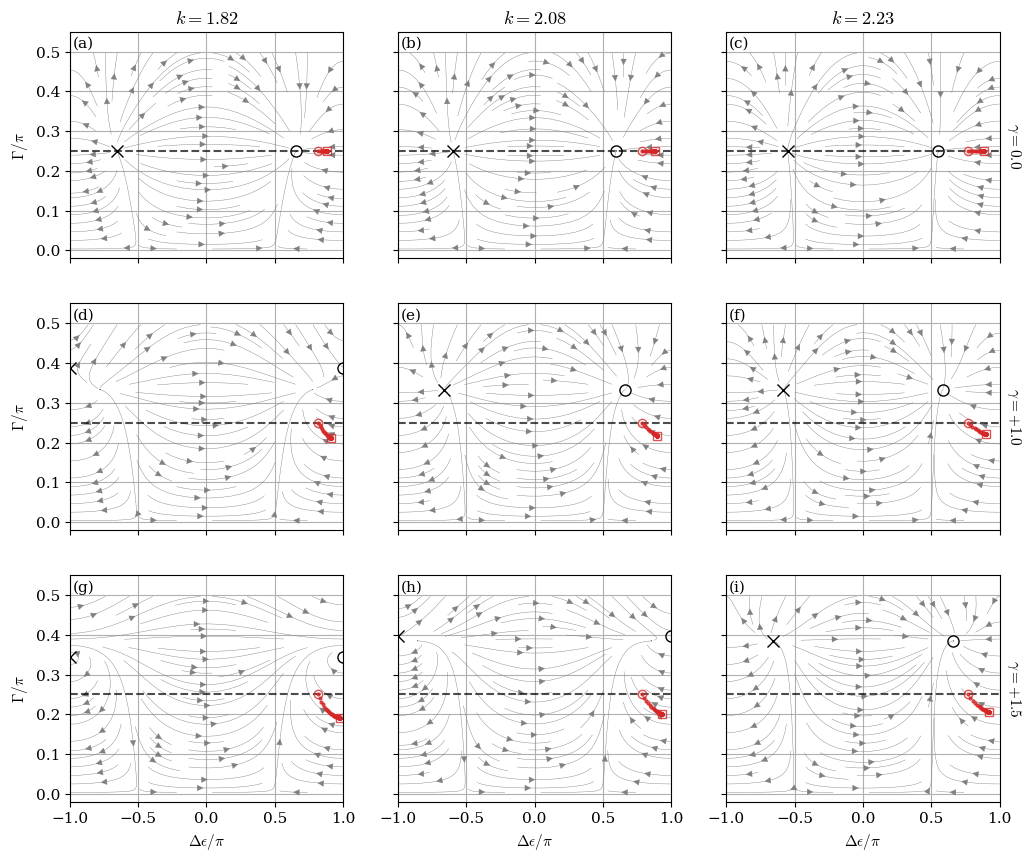

In [31]:
# phase protrait
dummy = 0
ll = 0
l = l_vec[ll]
k_vals = Phillips_k_max[:, ll]
# k_vals = [1.0, 1.5, 2.2]
T_vecs = np.linspace(1e-3, 5.0, 51)
delta = 0.0
fig, axs = plt.subplots(3,3,figsize=(12,10),sharex=True,sharey=True)

for row, gamma in enumerate(gamma_vec):
    for col, k in enumerate(k_vals):
        ax = axs[row, col]
        deps_grid, gamma_grid = np.meshgrid(np.linspace(-np.pi, np.pi, 101),np.linspace(0.01, np.pi/2 - 0.01, 101))
        points = np.asarray([deps_grid, gamma_grid])
        eps_dot, gamma_dot = dF(points,k,l,gamma,delta)
        ax.streamplot(deps_grid/np.pi,gamma_grid/np.pi,eps_dot,gamma_dot, color='gray', linewidth=0.3,density=0.8)
        ax.plot([-1.0, 1.0], [0.25, 0.25], 'k--', alpha=0.7)

        # Plot fixed points
        A = Phillips_A(k, l, gamma, delta)
        eigvals, eigvecs = np.linalg.eig(A)
        growth = np.max(np.real(eigvals))
        if growth > 1e-3:
            pos_root = get_root(dF,k,l, gamma, delta, guess_init=[0.25*np.pi, 0.25*np.pi])
            neg_root = get_root(dF,k,l, gamma, delta, guess_init=[-0.25*np.pi, 0.25*np.pi])
            ax.plot(pos_root[0]/np.pi,pos_root[1]/np.pi,'ko',markersize=8,markerfacecolor='none',markeredgewidth=1)
            ax.plot(neg_root[0]/np.pi,neg_root[1]/np.pi,'kx',markersize=8,markeredgewidth=1)

        else:
            pos_root = get_root(dF,k,l, gamma, delta, guess_init=[0.25*np.pi, 0.25*np.pi])
            neg_root = get_root(dF,k,l, gamma, delta, guess_init=[-0.25*np.pi, 0.1*np.pi])
            plot_root(ax, pos_root)
            plot_root(ax, neg_root)    

        # Plot ke-optimal points
        K = Phillips_KE(k, l)
        deps0_ke, gamma0_ke = compute_optimal(T_vecs, A, K)
        ax.plot(deps0_ke/np.pi,gamma0_ke/np.pi,'C3.', ms=4, alpha=0.8, label='Enstrophy')
        ax.plot(deps0_ke[0]/np.pi,gamma0_ke[0]/np.pi,'C3o',markerfacecolor='none',markersize=6, alpha=0.8, label=rf't={int(T_vecs[0])}')
        ax.plot(deps0_ke[-1]/np.pi,gamma0_ke[-1]/np.pi,'C3s',markerfacecolor='none',markersize=6, alpha=0.8, label=rf't={int(T_vecs[-1])}')
    

        ax.set_ylim([-0.02, 0.55])
        ax.grid()
        ax.set_title(rf'$k={k:.2f}$' if row == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$\Delta\epsilon/\pi$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$\Gamma/\pi$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\gamma={gamma_vec[row]:+.1f}$' if gamma_vec[row] != 0 else r'$\gamma=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

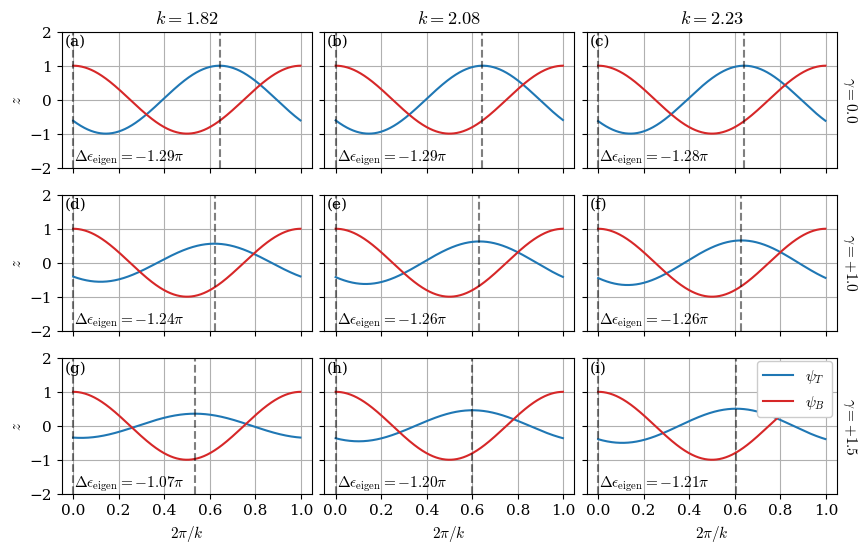

In [32]:
# streamfunction in KE norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 6), sharex=True, sharey=True)
for j in [0, 1, 2]:
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Phillips_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        psi_T = psi0_T_ke[0, :, i, j].copy()
        psi_B = psi0_B_ke[0, :, i, j].copy()
        psi_T /= psi_B[0]
        psi_B /= psi_B[0]
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_T), 'C0', label=r'$\psi_T$')
        ax.plot(x_vec/(2.0*np.pi/k), np.real(psi_B), 'C3', label=r'$\psi_B$')
        x_loc_T = x_vec[np.argmax(np.real(psi_T))] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(np.real(psi_B))] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-2.0, 2.0], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-2.0, 2.0], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.05, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={k:.2f}$" if j == 0 else "")
        ax.set_ylim(-2.0, 2.0)
        ax.grid()
        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")
    ax.xaxis.set_major_locator(MultipleLocator(0.2))

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\gamma={gamma_vec[idx]:+.1f}$" if gamma_vec[idx] != 0 else r"$\gamma=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
axs[-1,-1].legend(loc='upper right' ,bbox_to_anchor=(1.01, 1.03), framealpha=1.0)
fig.subplots_adjust(wspace=0.05)